# Lab 3 · Lost robot in a maze — Reinforcement Learning

**Fundamentals of AI** · No dataset this time — we build a tiny world ourselves.

A robot is dropped in an 8×8 maze. Traps are bad, the exit is great. Can it *learn* to
find the exit — just from rewards, with no map and no instructions?

# 🗺️ The ML project pipeline — RL edition

Reinforcement learning swaps *data & labels* for *world & rewards* — but it's the same skeleton:

| # | Pipeline step | Where in this lab |
|---|---------------|-------------------|
| 1 | **Define the world** — states, actions, rewards | §1 Setup & meet the maze |
| 2 | **Baseline agent** — random, no learning | §2 The clueless robot |
| 3 | **Design the learner** — Q-table + learning rule | §3 How the robot learns |
| 4 | **Train** — many episodes, watch the curve | §4 Train & watch it learn |
| 5 | **Evaluate** — replay & watch the learned policy | §5 Watch the trained robot |
| 6 | **Stress-test** — break the assumptions | §6 Break it |
| 7 | **Wrap up** — what you learned | §7 Takeaways |

## 1 · Set up the world — maze & rules

**Install libraries** (safe to skip on Colab).

In [43]:
#@title 0. Install libraries { display-mode: "form" }
# Colab already has these; this makes the notebook work anywhere. -q = quiet.
%pip -q install numpy matplotlib ipywidgets



[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


**Imports + helpers** — theme colors, `_warn` (print once), `need()` guard.

In [44]:
#@title 1a. Theme + helpers { display-mode: "form" }
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# dark theme colors (WALL = maze walls)
BG, ACCENT, ACCENT2, TEXT, RED, WALL = "#030503", "#00E676", "#3DFF8A", "#FFFFFF", "#FF5252", "#37474F"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": TEXT, "axes.labelcolor": TEXT, "axes.edgecolor": TEXT,
    "xtick.color": TEXT, "ytick.color": TEXT, "axes.titlecolor": TEXT,
    "grid.color": "#1c3a24", "font.size": 14, "axes.titlesize": 18,
    "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13,
    "figure.figsize": (8, 5),
})

_WARNED = set()   # remember which warnings we already printed (print once each)
def _warn(key, msg):
    if key not in _WARNED:
        print(msg); _WARNED.add(key)

def need(*names):
    """Friendly stop if an earlier step hasn't run yet."""
    missing = [n for n in names if n not in globals()]
    if missing:
        raise SystemExit(f"✏️ Not ready yet — missing: {', '.join(missing)}. Run the earlier cells first.")
print("Theme ready.")


Theme ready.


**The maze world** — layouts, shortest-safe-path (BFS), step/reward logic.

In [45]:
#@title 1b. The maze world (environment) { display-mode: "form" }
from collections import deque   # queue for breadth-first search

W = H = 8                                   # 8×8 grid
START, EXIT = (0, 0), (7, 7)                # top-left → bottom-right (row, col)
START_I, EXIT_I = 0, 63                     # same cells as flat indices 0..63
DIRS = [(-1,0),(1,0),(0,-1),(0,1)]          # up, down, left, right

# three maze layouts: walls block, traps end the episode badly
LAYOUTS = {
 "classic":  {"walls": {(0,4),(1,4),(2,4),(3,4),(4,4),(1,6),(2,6),(3,6),(5,2),(6,2)},
              "traps": {(2,2),(5,5),(6,4),(1,1)}},
 "shortcut": {"walls": {(3,3)},
              "traps": {(1,2),(2,1),(2,3),(3,2),(3,4),(4,3),(4,5),(5,4),(5,6),(6,5)}},
 "new_maze": {"walls": {(1,2),(1,4),(3,1),(3,3),(3,5),(5,2),(5,4),(5,6),(7,1),(7,5),(0,3),(2,6),(4,0),(6,3)},
              "traps": {(4,4),(6,5),(1,6),(5,0)}},
}

def bfs_path(walls, traps):
    """Shortest SAFE path (flat indices) from start to exit, avoiding walls AND traps."""
    q, seen, parent = deque([START]), {START}, {}
    while q:
        cell = q.popleft()                  # BFS: first time we pop EXIT = shortest
        if cell == EXIT:
            path = [cell]
            while cell != START:            # walk parents backward to the start
                cell = parent[cell]
                path.append(cell)
            return [r*W + c for r, c in path[::-1]]
        r, c = cell
        for dr, dc in DIRS:
            n = (r+dr, c+dc)
            # in bounds, not a wall, not a trap, not visited → enqueue
            if 0 <= n[0] < 8 and 0 <= n[1] < 8 and n not in walls and n not in traps and n not in seen:
                seen.add(n); parent[n] = cell; q.append(n)
    return None

def bfs_len(walls, traps):
    """Shortest SAFE path (steps) from start to exit, avoiding walls AND traps."""
    path = bfs_path(walls, traps)
    return None if path is None else len(path) - 1

def step(s, a):
    """One move. Returns (new_state, reward, done). Reads global ENV."""
    r, c = divmod(s, W)                      # flat index → (row, col)
    if np.random.rand() < ENV["slip_prob"]:  # slip! move a random way instead
        a = np.random.randint(4)
    dr, dc = DIRS[a]; nr, nc = r+dr, c+dc
    if not (0 <= nr < 8 and 0 <= nc < 8) or (nr, nc) in ENV["walls"]:
        nr, nc = r, c                        # bump into wall/out of bounds: stay put
    ns = nr*W + nc                            # back to flat index
    if (nr, nc) == EXIT:  return ns, ENV["exit_reward"], True    # episode ends, big reward
    if (nr, nc) in ENV["traps"]: return ns, ENV["trap_penalty"], True
    return ns, ENV["step_penalty"], False    # normal move: small cost, keep going

def rollout(act_fn=None, max_steps=200):
    """Run one episode. act_fn(s)->action, or None = random."""
    s, done, steps, rew, trapped, path = START_I, False, 0, 0, False, [START_I]
    while not done and steps < max_steps:
        a = act_fn(s) if act_fn else np.random.randint(4)   # policy or random
        s, r, done = step(s, a)
        steps += 1; rew += r; path.append(s)
        if tuple(divmod(s, W)) in ENV["traps"]: trapped = True
    return {"steps": steps, "reward": rew, "trapped": trapped, "path": path}

**Maze drawer** — the function that draws walls, traps, path, policy, robot.

In [46]:
#@title 1c. Maze drawer { display-mode: "form" }
def draw_maze(robot=None, path=None, policy=None, title="", ax=None, walls=None, traps=None):
    """Draw the grid: walls grey, traps red, exit glowing green, robot green dot.
    policy = (8,8) array of action indices → arrows. Returns ax."""
    from matplotlib.patches import Rectangle, Circle
    walls = ENV["walls"] if walls is None else walls
    traps = ENV["traps"] if traps is None else traps
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.set_xlim(-0.6, 7.6); ax.set_ylim(7.6, -0.6); ax.set_aspect("equal")
    ax.axis("off")
    for r in range(8):
        for c in range(8):
            x, y = c - 0.5, 7 - r - 0.5          # display coords: row 0 on top
            cell = (r, c)
            # pick the cell color by what lives there
            if cell in walls:   fc = WALL
            elif cell in traps: fc = RED
            elif cell == EXIT:        fc = ACCENT
            else:                     fc = "#0a140d"
            ax.add_patch(Rectangle((x, y), 1, 1, facecolor=fc, edgecolor="#1c3a24", lw=0.5))
    ax.text(7.0, 0.15, "EXIT", color=BG, fontsize=10, ha="center", fontweight="bold")
    # draw the traveled path as a line (list of flat indices)
    if path is not None and len(path) > 1:
        xs = [i % 8 for i in path]; ys = [7 - i//8 for i in path]
        ax.plot(xs, ys, color=ACCENT, lw=2, alpha=0.8)
    # draw policy arrows: one arrow per free cell pointing at its best action
    if policy is not None:
        for r in range(8):
            for c in range(8):
                cell = (r, c)
                if cell in walls or cell in traps or cell == EXIT: continue
                dr, dc = DIRS[policy[r, c]]
                ax.arrow(c, 7 - r, 0.3*dc, -0.3*dr, head_width=0.12,
                         color=ACCENT2, alpha=0.8)
    # draw the robot as a green dot
    if robot is not None:
        r, c = robot
        ax.add_patch(Circle((c - 0.5 + 0.5, 7 - r - 0.5 + 0.5), 0.22,
                            facecolor=ACCENT2, edgecolor="white", lw=1.5, zorder=5))
    if title: ax.set_title(title, color=TEXT, fontsize=16, pad=10)
    if own: plt.tight_layout(); plt.show()
    return ax

**Pick a layout + rewards** — sliders set the world's rules.

layout=classic | rewards: step -1.0, trap -10.0, exit 100.0, slip 0.0
Shortest SAFE path (BFS, avoids walls+traps): 14 steps


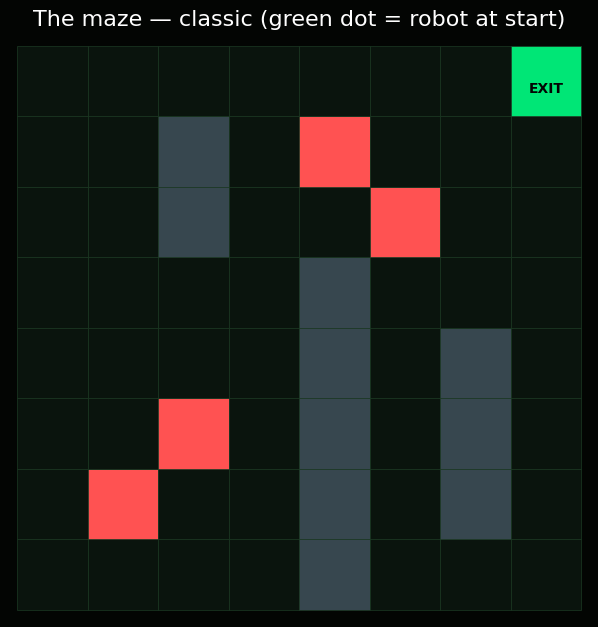

<Axes: title={'center': 'The maze — classic (green dot = robot at start)'}>

In [47]:
#@title 1d. Choose layout & world knobs
#@param {"type":"select","label":"maze layout","options":["classic","shortcut","new_maze"]}
layout = "classic"
#@param {"type":"slider","min":-5,"max":0,"step":0.5,"label":"step_penalty (cost per move)"}
step_penalty = -1.0
#@param {"type":"slider","min":-50,"max":-1,"step":1,"label":"trap_penalty"}
trap_penalty = -10.0
#@param {"type":"slider","min":10,"max":200,"step":10,"label":"exit_reward"}
exit_reward = 100.0
#@param {"type":"slider","min":0,"max":0.5,"step":0.05,"label":"slip_prob (random moves)"}
slip_prob = 0.0

np.random.seed(42)   # repeatable runs
# pack the chosen layout + knob values into one dict the world reads
ENV = dict(walls=LAYOUTS[layout]["walls"], traps=LAYOUTS[layout]["traps"],
           step_penalty=step_penalty, trap_penalty=trap_penalty,
           exit_reward=exit_reward, slip_prob=slip_prob)
# defaults saved so load_layout() can reset knobs when switching mazes
DEFAULT_PARAMS = dict(step_penalty=-1.0, trap_penalty=-10.0, exit_reward=100.0, slip_prob=0.0)

def load_layout(name):
    """Switch maze, reset world knobs to defaults. Returns shortest SAFE path."""
    global ENV   # we rebind ENV, so it must be declared global
    ENV = dict(LAYOUTS[name], **DEFAULT_PARAMS)
    return bfs_len(ENV["walls"], ENV["traps"])

# BFS gives us the "perfect play" distance — a useful reference for later
safe = bfs_len(ENV["walls"], ENV["traps"])
print(f"layout={layout} | rewards: step {ENV['step_penalty']}, trap {ENV['trap_penalty']}, "
      f"exit {ENV['exit_reward']}, slip {ENV['slip_prob']}")
print(f"Shortest SAFE path (BFS, avoids walls+traps): {safe} steps")
draw_maze(title=f"The maze — {layout} (green dot = robot at start)")

**All layouts at a glance** — the green line is the shortest SAFE path for each maze (BFS, avoiding walls and traps).

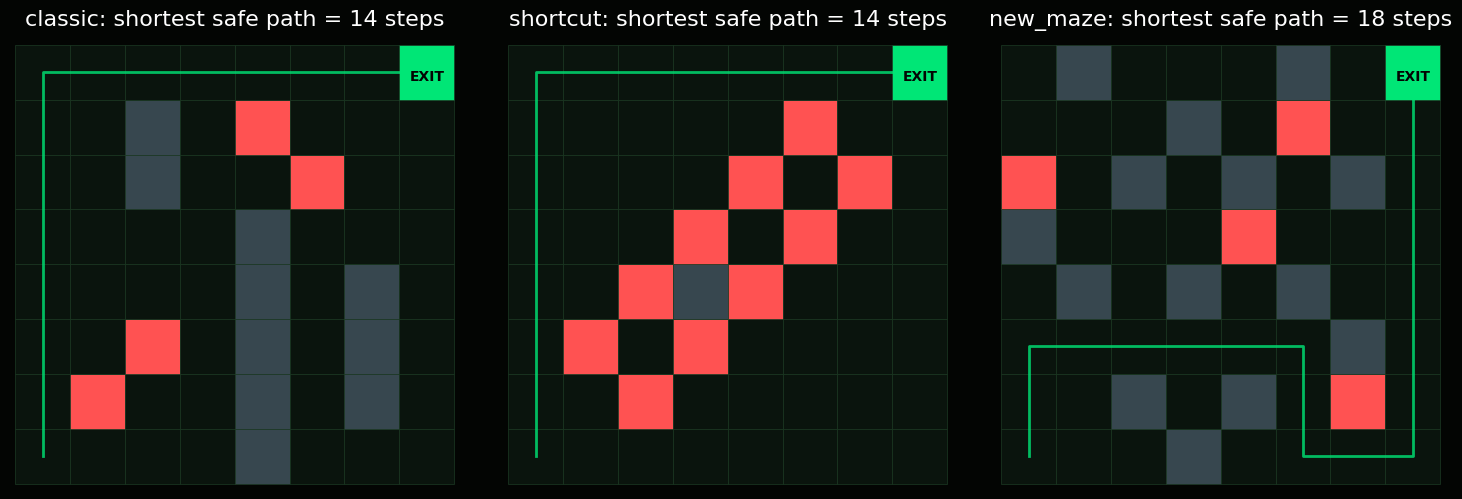

In [48]:
#@title 1e. All mazes + shortest safe paths { display-mode: "form" }
need("bfs_path", "LAYOUTS", "draw_maze")
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, maze) in zip(axs, LAYOUTS.items()):
    path = bfs_path(maze["walls"], maze["traps"])
    label = "no safe path" if path is None else f"shortest safe path = {len(path) - 1} steps"
    draw_maze(path=path, walls=maze["walls"], traps=maze["traps"],
              title=f"{name}: {label}", ax=ax)
fig.tight_layout()
plt.show()

## 2 · Baseline — the clueless robot

A robot that picks **random actions** every step. No learning, no plan.

> 📝 **Predict-then-run:** how many steps do you think it needs to reach the exit —
> and how often does it fall into a trap? Then run the next two cells.

**Random agent** — 300 episodes, no learning.

In [49]:
#@title 2a. Random agent — 300 episodes { display-mode: "form" }
need("rollout", "ENV")
# rollout() with no act_fn = random actions every step; run 300 episodes
res = [rollout() for _ in range(300)]
steps = np.array([r["steps"] for r in res])          # steps taken per episode
trapped = np.mean([r["trapped"] for r in res])       # fraction that hit a trap
exits = np.mean([r["path"][-1] == EXIT_I for r in res])  # fraction that reached exit
print(f"Random agent over 300 episodes:")
print(f"  mean steps: {steps.mean():.0f}   (max allowed: 200)")
print(f"  fell into a trap: {trapped*100:.0f}%")
print(f"  reached the exit: {exits*100:.1f}%")

Random agent over 300 episodes:
  mean steps: 11   (max allowed: 200)
  fell into a trap: 100%
  reached the exit: 0.0%


**Watch one random episode** — see how bad wandering is.

One random episode: 22 steps → TRAP


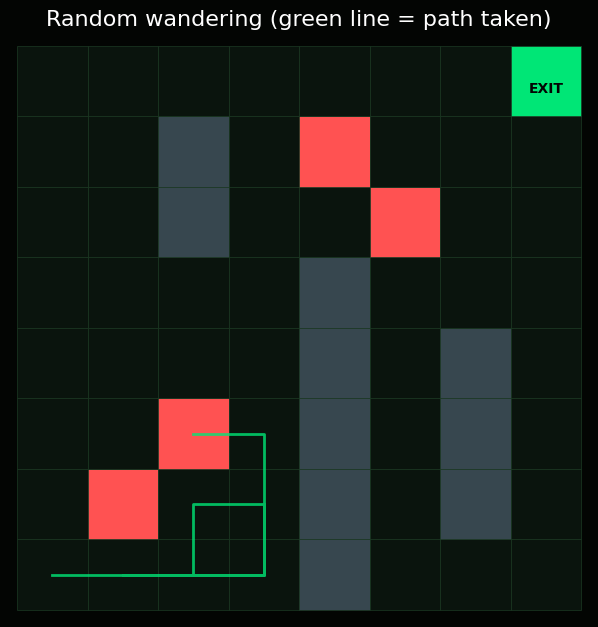

<Axes: title={'center': 'Random wandering (green line = path taken)'}>

In [50]:
#@title 2b. Watch one random episode { display-mode: "form" }
need("rollout")
demo = rollout()   # one random episode, recorded as a path of cells
path_cells = [divmod(s, 8) for s in demo["path"]]   # flat index → (row, col)
# how did it end? exit, trap, or hit the 200-step limit
end = "EXIT" if demo["path"][-1] == EXIT_I else ("TRAP" if demo["trapped"] else "gave up")
print(f"One random episode: {demo['steps']} steps → {end}")
draw_maze(path=demo["path"], title="Random wandering (green line = path taken)")

<details><summary>💡 Why so bad?</summary>

64 cells × 4 actions = 256 state-action pairs, and the robot has **no idea** which are
good. Random walk in a maze with traps is hopeless — it needs a way to *remember*
what worked. That's what Q-learning adds.</details>

## 3 · Design the learner — Q-learning

The robot keeps a **Q-table**: for every (cell, action) pair, a score = "how good is
this move *from here*?"

```
           up    down   left   right
cell 34   2.1   -0.4    1.2     0.3     ← robot picks the max (up)
cell 35  -1.0    8.9    0.1    -0.5
```

After each move it updates the score with the **Q-learning rule**:

> `Q(s,a) ← Q(s,a) + α · ( reward + γ · bestNextQ − Q(s,a) )`
>
> α = learning rate (how fast to trust new info), γ = discount (how much future rewards count).

And it chooses actions **epsilon-greedy**: mostly take the best known move, but with
probability ε try a random one (exploration!).

**Epsilon-greedy action choice** — explore randomly sometimes, else take the best-known move.

In [51]:
def choose_action(Q, s, eps):
    """Epsilon-greedy: with prob eps explore (random action), else exploit (best Q)."""
    # Q[s] = the 4 Q-values for this cell; argmax picks the best-known action
    if np.random.rand() < eps:                 # explore: random action
        return np.random.randint(4)
    return int(np.argmax(Q[s]))                # exploit: action with highest Q-value

**Q-learning update** — the rule that nudges Q toward reward + future value.

In [52]:
def q_update(Q, s, a, r, s2, done, alpha, gamma):
    """One Q-learning update."""
    # if the episode ended, there's no future → best_next = 0
    best_next = 0.0 if done else float(np.max(Q[s2]))
    # Q-learning rule: move Q[s,a] toward (reward + discounted best future value)
    Q[s, a] = Q[s, a] + alpha * (r + gamma * best_next - Q[s, a])

**The training loop** — already written; it calls the two functions above.

In [53]:
#@title 3b. The training loop (already written) { display-mode: "form" }
need("choose_action", "q_update", "ENV")

def train(Q, episodes, eps0=0.3, alpha=0.5, gamma=0.95):
    """Run Q-learning for `episodes` episodes. Returns (Q, rewards, steps)."""
    hr, hs = [], []   # per-episode total reward and step count (for the learning curve)
    for ep in range(episodes):
        s, done, steps, tot = START_I, False, 0, 0
        # explore a lot early, almost never late (linear decay to 0.02)
        eps = max(0.02, eps0 * (1 - ep / max(episodes - 1, 1)))
        while not done and steps < 200:
            a = choose_action(Q, s, eps)      # your Blank #1
            s2, r, done = step(s, a)          # take the action, get reward
            q_update(Q, s, a, r, s2, done, alpha, gamma)   # your Blank #2
            s, steps, tot = s2, steps + 1, tot + r
        hr.append(tot); hs.append(steps)
    return Q, hr, hs
print("train() ready — it calls your two blanks above.")

train() ready — it calls your two blanks above.


<details><summary>💡 Checkpoint — what do α and γ do?</summary>

- **α (learning rate):** how much each new experience overwrites the old guess.
  α=1 → forget everything instantly; α→0 → never learn.
- **γ (discount):** how much a reward *one step in the future* is worth vs now.
  γ=0 → greedy, only cares about the immediate reward; γ≈0.95 → plans ahead
  (a trap 5 steps away still scares it because the penalty propagates back).</details>

## 4 · Train the agent

Run `train()` with the knobs below, then look at the learning curve —
reward should climb, steps should drop.

**Train** — set the knobs and run Q-learning.

In [54]:
#@title 4a. Training knobs
#@param {"type":"slider","min":0.05,"max":1.0,"step":0.05,"label":"epsilon0 (initial exploration)"}
eps0 = 0.3
#@param {"type":"slider","min":0.05,"max":1.0,"step":0.05,"label":"alpha (learning rate)"}
alpha = 0.5
#@param {"type":"slider","min":0.8,"max":0.99,"step":0.01,"label":"gamma (discount)"}
gamma = 0.95
#@param {"type":"slider","min":100,"max":2000,"step":100,"label":"episodes"}
episodes = 500

need("train", "ENV")
# Q-table: one row per cell (64), 4 columns = Q-value per action
Q = np.zeros((W*W, 4))
Q, hr, hs = train(Q, episodes=episodes, eps0=eps0, alpha=alpha, gamma=gamma)
# show the average over the last 50 episodes — the "converged" behavior
print(f"After {episodes} episodes:")
print(f"  mean reward (last 50): {np.mean(hr[-50:]):.1f}")
print(f"  mean steps  (last 50): {np.mean(hs[-50:]):.1f}")

After 500 episodes:
  mean reward (last 50): 84.7
  mean steps  (last 50): 14.1


**Learning curve** — did reward climb and steps drop?

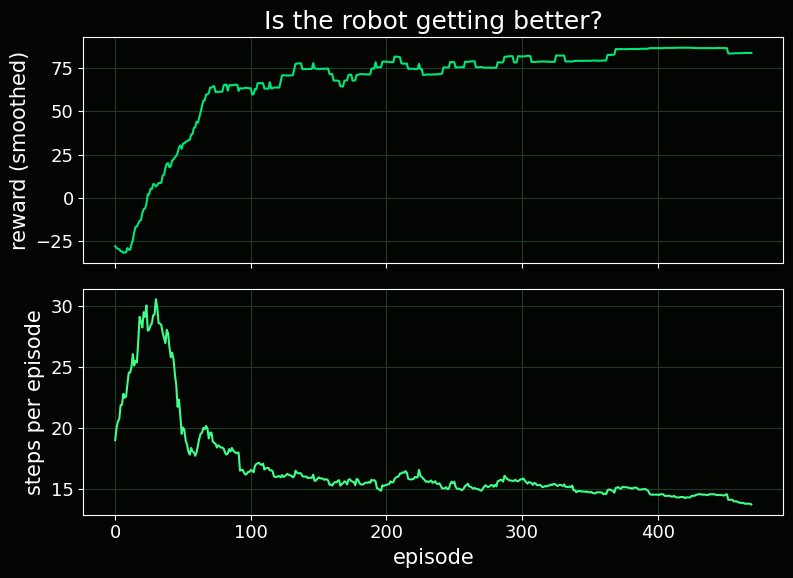

In [55]:
#@title 4b. Learning curve { display-mode: "form" }
need("hr", "hs")
def smooth(x, w=31):
    # moving average over a window of 31 episodes — less noisy curve
    return np.convolve(np.asarray(x, float), np.ones(w)/w, "valid")

fig, axs = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axs[0].plot(smooth(hr), color=ACCENT); axs[0].set_ylabel("reward (smoothed)")
axs[0].set_title("Is the robot getting better?")
axs[1].plot(smooth(hs), color=ACCENT2); axs[1].set_ylabel("steps per episode")
axs[1].set_xlabel("episode")
for ax in axs: ax.grid(True, color="#1c3a24")
plt.tight_layout(); plt.show()

## 5 · Evaluate — watch it play

The Q-table *is* the policy: at each cell, take the action with the highest Q.
First the arrows, then a replay.

**Policy as arrows** — best action per cell, straight from the Q-table.

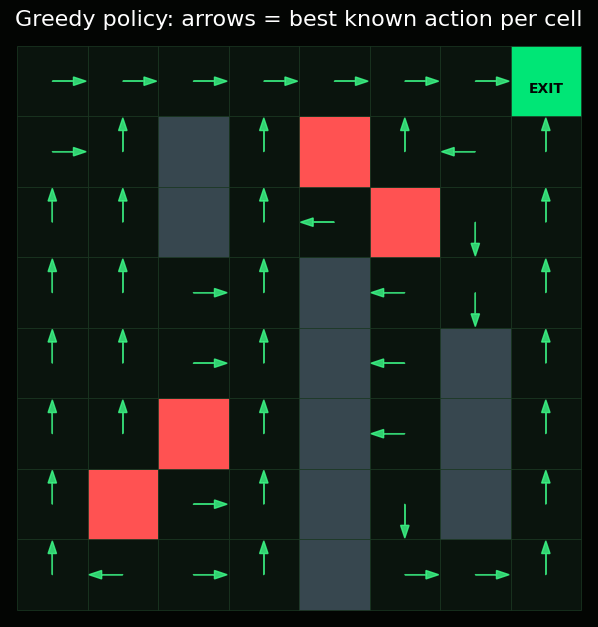

<Axes: title={'center': 'Greedy policy: arrows = best known action per cell'}>

In [56]:
#@title 5a. Learned policy — arrows on the maze { display-mode: "form" }
need("Q")
# reshape Q from (64, 4) to (8, 8, 4) so argmax gives best action per cell
pi = np.argmax(Q.reshape(8, 8, 4), axis=2)
draw_maze(policy=pi, title="Greedy policy: arrows = best known action per cell")

**Replay one episode** — greedy policy, animated.

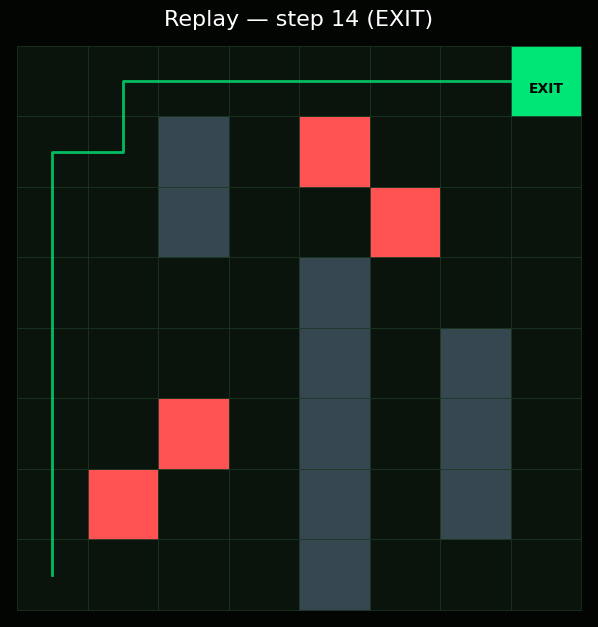

Replay finished.


In [57]:
#@title 5b. Replay one episode { display-mode: "form" }
need("Q")
import time
from IPython.display import clear_output

# greedy replay: always take the best-known action (no exploration)
s, done, path = START_I, False, [START_I]
for t in range(200):
    clear_output(wait=True)   # redraw in place → animation effect
    end = "EXIT" if s == EXIT_I else ("TRAP" if tuple(divmod(s, W)) in ENV["traps"] else "...")
    draw_maze(path=path, title=f"Replay — step {t} ({end})")
    if done or s == EXIT_I or tuple(divmod(s, W)) in ENV["traps"]: break
    a = int(np.argmax(Q[s]))              # greedy action
    s, r, done = step(s, a); path.append(s)
    time.sleep(0.2)                       # pause so you can follow it
print("Replay finished.")

## 6 · Stress-test — break it

Three mini-experiments. For each: **predict what happens, then run.**

> 🧠 Meta-note: retraining Q from scratch for every new maze is slow and wasteful.
> *Meta-learning* tries to learn **how to learn** faster — a glimpse of the next level.

### 6a · Free steps — what if moving costs nothing?

Set `step_penalty = 0` below and retrain. **Expect:** the robot stops caring about
efficiency — watch mean steps per episode.

**Free steps** — `step_penalty = 0`, retrain, watch mean steps.

In [58]:
#@title 6a. step_penalty = 0 experiment { display-mode: "form" }
need("train", "ENV")
ENV["step_penalty"] = 0.0          # moves are now FREE — only traps & exit matter
# fresh Q-table, retrain from scratch under the new reward rules
Q_a = np.zeros((W*W, 4))
Q_a, hr_a, hs_a = train(Q_a, episodes=500, eps0=0.3, alpha=0.5, gamma=0.95)
print(f"mean steps (last 50): {np.mean(hs_a[-50:]):.1f}   (baseline was ~15)")
# test the greedy policy once
res = rollout(lambda s: int(np.argmax(Q_a[s])))
print(f"greedy rollout: {res['steps']} steps, trapped={res['trapped']}, reached_exit={res['path'][-1]==EXIT_I}")

mean steps (last 50): 169.2   (baseline was ~15)
greedy rollout: 200 steps, trapped=False, reached_exit=False


### 6b · The risky shortcut

Layout **shortcut** has a minefield of traps across the direct route; a safe path is longer.
With `slip_prob = 0.2` the robot sometimes moves randomly — near traps that's dangerous.

**Predict:** will it hug the traps or take the long way around?

**Shortcut + slips** — retrain with `slip_prob = 0.2`.

shortcut | shortest SAFE path = 14 steps | slip = 0.2


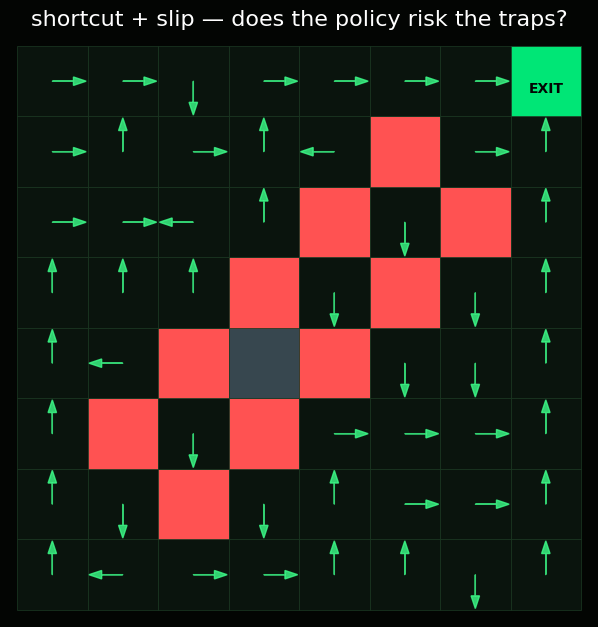

<Axes: title={'center': 'shortcut + slip — does the policy risk the traps?'}>

In [59]:
#@title 6b1. shortcut + slip_prob = 0.2 { display-mode: "form" }
need("train", "load_layout")
safe = load_layout("shortcut")   # switch maze + reset knobs to defaults
ENV["slip_prob"] = 0.2           # now 20% of moves go a random direction
print(f"shortcut | shortest SAFE path = {safe} steps | slip = 0.2")
Q_b = np.zeros((W*W, 4))
Q_b, _, _ = train(Q_b, episodes=800, eps0=0.3, alpha=0.5, gamma=0.95)
pi_b = np.argmax(Q_b.reshape(8, 8, 4), axis=2)
draw_maze(policy=pi_b, title="shortcut + slip — does the policy risk the traps?")

**Make traps cheaper** — retrain and see if the policy gets riskier.

trap_penalty=-2 → greedy rollout: 3 steps, trapped=True


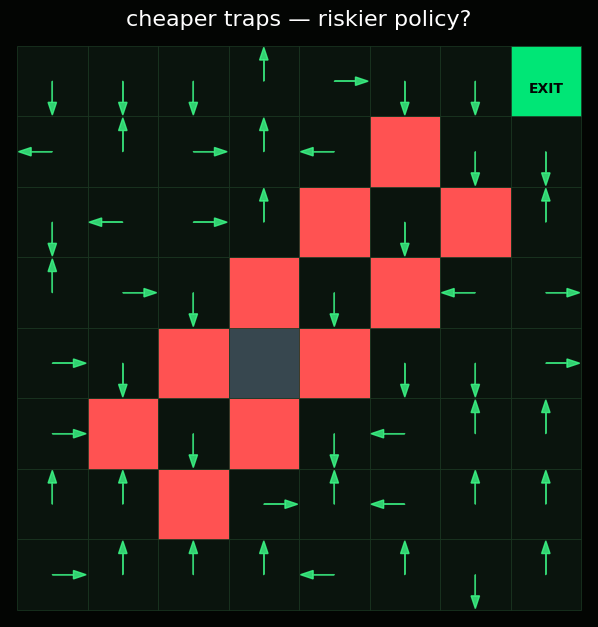

<Axes: title={'center': 'cheaper traps — riskier policy?'}>

In [60]:
#@title 6b2. Now make traps cheaper { display-mode: "form" }
need("train", "ENV", "rollout")
ENV["trap_penalty"] = -2.0         # falling in a trap barely hurts now
# retrain on the same shortcut+slip world with the cheaper trap penalty
Q_b2 = np.zeros((W*W, 4))
Q_b2, _, _ = train(Q_b2, episodes=800, eps0=0.3, alpha=0.5, gamma=0.95)
res = rollout(lambda s: int(np.argmax(Q_b2[s])))
print(f"trap_penalty=-2 → greedy rollout: {res['steps']} steps, trapped={res['trapped']}")
draw_maze(policy=np.argmax(Q_b2.reshape(8,8,4),axis=2), title="cheaper traps — riskier policy?")

### 6c · New maze, old brain

Switch to **new_maze** — walls and traps moved. Apply the **classic-trained Q**
(`Q` from section 4) without retraining.

**Predict:** does the old policy still work?

**Old brain, new maze** — apply the classic-trained Q without retraining.

new_maze | shortest SAFE path = 18 steps
BEFORE retraining — OLD policy: 200 steps, trapped=False, reached_exit=False


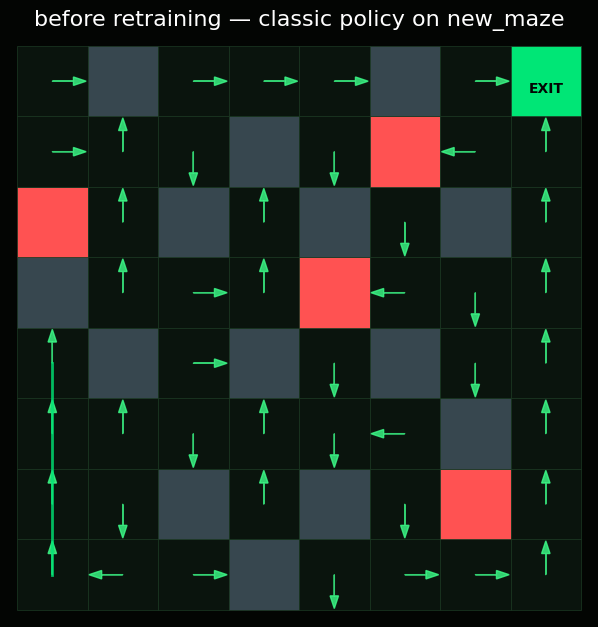

<Axes: title={'center': 'before retraining — classic policy on new_maze'}>

In [61]:
#@title 6c1. Old Q-table on new_maze { display-mode: "form" }
need("Q", "load_layout", "rollout")
safe = load_layout("new_maze")   # switch maze — walls/traps moved, Q stays the same
print(f"new_maze | shortest SAFE path = {safe} steps")
# reuse the classic-trained Q without any retraining — will it still work?
res_before = rollout(lambda s: int(np.argmax(Q[s])))
print(f"BEFORE retraining — OLD policy: {res_before['steps']} steps, trapped={res_before['trapped']}, "
      f"reached_exit={res_before['path'][-1]==EXIT_I}")
pi_old = np.argmax(Q.reshape(8,8,4), axis=2)
draw_maze(policy=pi_old, path=res_before["path"],
          title="before retraining — classic policy on new_maze")

**Retrain on the new maze** — fresh Q-table, same knobs.

AFTER retraining — last-50 steps 18.4 | rollout 18 steps, trapped=False, reached_exit=True


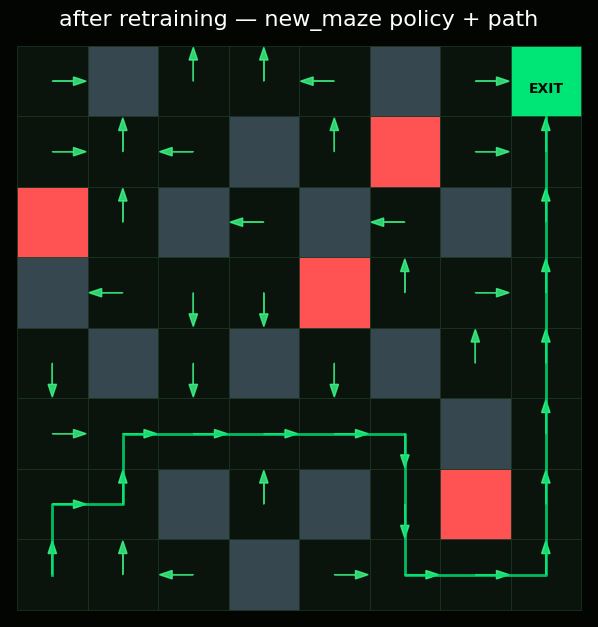

<Axes: title={'center': 'after retraining — new_maze policy + path'}>

In [62]:
#@title 6c2. Retrain on new_maze { display-mode: "form" }
need("train", "ENV", "rollout")
# fresh Q-table, retrain on the new maze layout
Q_n = np.zeros((W*W, 4))
Q_n, hr_n, hs_n = train(Q_n, episodes=800, eps0=0.3, alpha=0.5, gamma=0.95)
res_after = rollout(lambda s: int(np.argmax(Q_n[s])))
print(f"AFTER retraining — last-50 steps {np.mean(hs_n[-50:]):.1f} | rollout {res_after['steps']} steps, "
      f"trapped={res_after['trapped']}, reached_exit={res_after['path'][-1]==EXIT_I}")
pi_n = np.argmax(Q_n.reshape(8,8,4), axis=2)
draw_maze(policy=pi_n, path=res_after["path"],
          title="after retraining — new_maze policy + path")

## Export the model

Save the trained Q-table(s) to a `models/` folder — the Q-table *is* the learned policy.

In [63]:
#@title Export the Q-table(s) { display-mode: "form" }
import os
import numpy as np
os.makedirs("models", exist_ok=True)

# pick up every trained Q-table whose cell was run
qtables = {k: globals()[k] for k in ("Q", "Q_a", "Q_b", "Q_b2", "Q_n")
           if isinstance(globals().get(k), np.ndarray)}
if not qtables:
    raise SystemExit("No Q-tables found — run §4 first.")

path = "models/lab3_qtables.npz"
np.savez(path, **qtables)          # one .npz archive holding all the Q-tables
print(f"saved {path}")
print("Contents:", {k: v.shape for k, v in qtables.items()})
print("\nReload later with:")
print("  data = np.load('models/lab3_qtables.npz')")
print("  Q = data['Q']   # classic-maze policy; 'Q_n' is the new_maze one")
print("\n⚠️ Each Q-table only works on the maze layout it was trained on.")

saved models/lab3_qtables.npz
Contents: {'Q': (64, 4), 'Q_a': (64, 4), 'Q_b': (64, 4), 'Q_b2': (64, 4), 'Q_n': (64, 4)}

Reload later with:
  data = np.load('models/lab3_qtables.npz')
  Q = data['Q']   # classic-maze policy; 'Q_n' is the new_maze one

⚠️ Each Q-table only works on the maze layout it was trained on.


## 7 · Takeaways

- The robot learns a **policy** (best action per cell) from **rewards alone** — no map, no labels.
- **Q-table** = memory of "how good is this move here"; updated by reward + discounted future.
- **ε-greedy** balances explore vs exploit; **α, γ** control learning speed and foresight.
- New world → old Q fails → **retrain**. (Meta-learning tries to make that faster.)
- Real RL (games, robotics, LLMs) is the same loop at massive scale.

🎉 Lab 3 complete.